**Гипотеза 3.** По подсчетам количество дней когда идет дождь около 600, стоит ли оборудовать 30% всех велосипедов под дождь.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

- читаю файл "../../../data_after_preprocessing/drd_with_weather.parquet"

In [2]:
drd_with_weather = pd.read_parquet('../../../data_after_preprocessing/drd_with_weather.parquet')
drd_with_weather

,rideable_type,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes
0,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.17,0.0,rain,1499.883301
1,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,3.600000,41.900002,-5.700000,16.0,40.799999,0.00,0.0,partly-cloudy-day,24.483334
2,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,18.000000,18.000000,82.300003,14.900000,15.8,20.900000,0.00,0.0,cloudy,16.533333
3,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,22.200001,79.199997,18.200001,15.8,17.500000,0.00,0.0,partly-cloudy-day,17.350000
4,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,20.400000,39.500000,6.000000,16.0,28.500000,0.00,0.0,partly-cloudy-day,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,31.900000,64.500000,21.600000,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800
16086668,electric_bike,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.00,0.0,rain,16.411934
16086669,electric_bike,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,6.182117
16086670,electric_bike,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,10.186934


- выбираю погодные условия дождь

In [3]:
weather_rain = drd_with_weather[drd_with_weather['icon'] == 'rain']
weather_rain

,rideable_type,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes
0,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.170000,0.0,rain,1499.883301
5,docked_bike,2020-05-30 20:23:38.000,2020-05-30 20:46:36.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.170000,0.0,rain,22.966667
7,docked_bike,2020-05-23 14:42:17.000,2020-05-23 15:52:05.000,casual,2020-05-23,22.799999,22.799999,72.300003,16.900000,15.6,22.900000,20.830000,0.0,rain,69.800003
11,docked_bike,2020-05-15 19:13:33.000,2020-05-16 20:13:27.000,casual,2020-05-15,22.799999,22.799999,65.599998,15.200000,16.0,32.400002,4.170000,0.0,rain,1499.900024
13,docked_bike,2020-05-23 14:34:58.000,2020-05-23 14:51:59.000,casual,2020-05-23,22.799999,22.799999,72.300003,16.900000,15.6,22.900000,20.830000,0.0,rain,17.016666
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086665,electric_bike,2024-08-10 19:53:27.500,2024-08-10 20:02:00.576,member,2024-08-10,27.799999,28.700001,66.300003,20.500000,16.0,16.400000,4.170000,0.0,rain,8.551267
16086666,electric_bike,2024-08-09 21:48:44.578,2024-08-09 22:14:06.567,member,2024-08-09,27.000000,28.799999,82.400002,23.700001,13.9,37.900002,58.330002,0.0,rain,25.366484
16086668,electric_bike,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.000000,0.0,rain,16.411934
16086669,electric_bike,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.500000,0.0,rain,6.182117


- считаю сколько дней шел дождь

In [4]:
weather_rain['date'].nunique()

596

- добавлю столбец год, что бы затем рассчитать количество дней, когда был дождь

In [5]:
drd_with_weather['year'] = drd_with_weather['date'].dt.year

- еще добавлю количество дней за каждый год (погода дождь)

In [6]:
rain_days_by_year = (
    drd_with_weather[drd_with_weather['icon'] == 'rain']
    .groupby('year')['date']
    .nunique()
)
rain_days_by_year

year
2020    106
2021    127
2022    129
2023    139
2024     95
Name: date, dtype: int64

- вывожу график количество дождливых дней по годам

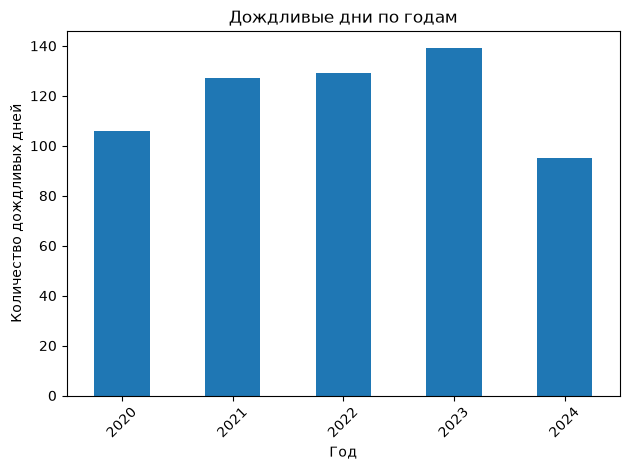

In [7]:
ax = rain_days_by_year.plot(kind='bar')
ax.set_xlabel('Год')
ax.set_ylabel('Количество дождливых дней')
ax.set_title('Дождливые дни по годам')
plt.xticks(rotation=45)      
plt.tight_layout()
plt.show()

- сейчас хочу вывести информацию по всем погодным условиям и посмотеть сколько в минутах и сколько аредны в минутах получается

In [8]:
all_weather = drd_with_weather.groupby('icon')['duration_in_minutes'].sum()
all_weather

icon
clear-day            1.895502e+07
cloudy               6.895602e+06
partly-cloudy-day    2.221768e+08
rain                 1.387418e+08
snow                 1.495900e+06
wind                 4.119880e+05
Name: duration_in_minutes, dtype: float32

- вывожу график с различными погодными условиями

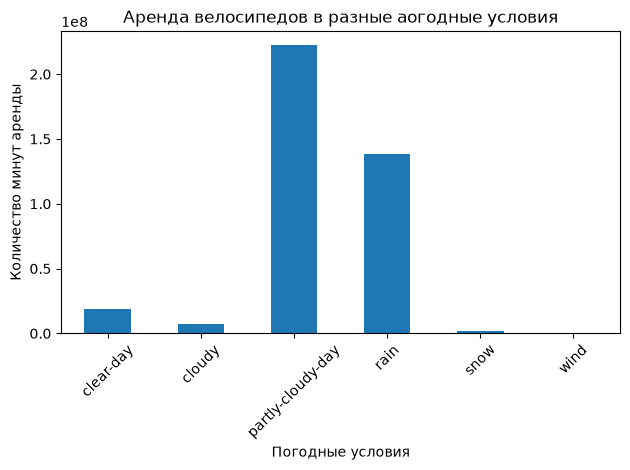

In [9]:
ax = all_weather.plot(kind='bar')
ax.set_xlabel('Погодные условия')
ax.set_ylabel('Количество минут аренды')
ax.set_title('Аренда велосипедов в разные аогодные условия')
plt.xticks(rotation=45)      
plt.tight_layout()
plt.show()

- теперь хочу посмотреть все погодные условия и вывести все погодные условия по всем годам на график

In [10]:
all_weather_of_years = drd_with_weather.groupby(['year', 'icon'])['duration_in_minutes'].sum().to_frame()
all_weather_of_years

duration_in_minutes
year icon                                  
2020 clear-day                 3.915423e+06
     cloudy                    1.941130e+06
     partly-cloudy-day         3.842611e+07
     rain                      3.460436e+07
     snow                      5.808737e+04
     wind                      1.309285e+05
2021 clear-day                 1.824763e+06
     cloudy                    1.982406e+06
     partly-cloudy-day         4.325232e+07
     rain                      2.113859e+07
     snow                      4.006871e+05
     wind                      2.810595e+05
2022 clear-day                 4.470078e+06
     cloudy                    8.710348e+05
     partly-cloudy-day         4.954542e+07
     rain                      2.723635e+07
     snow                      4.904599e+05
2023 clear-day                 6.399824e+06
     cloudy                    1.669467e+06
     partly-cloudy-day         5.286396e+07
     rain                      3.234909e+07
     snow                      2.224532e+05
2024 clear-day                 2.344935e+06
     cloudy                    4.315646e+05
     partly-cloudy-day         3.808894e+07
     rain                      2.341337e+07
     snow                      3.242123e+05

- подготавливаю таблицу

In [11]:
pivot = all_weather_of_years['duration_in_minutes'].unstack('icon')
pivot = pivot[['clear-day', 'cloudy', 'partly-cloudy-day', 'rain', 'snow', 'wind']]  

In [12]:
pivot

icon,clear-day,cloudy,partly-cloudy-day,rain,snow,wind
year,,,,,,
2020,3915423.25,1.941130e+06,38426108.0,34604356.0,58087.367188,130928.515625
2021,1824762.75,1.982406e+06,43252316.0,21138592.0,400687.093750,281059.500000
2022,4470078.50,8.710348e+05,49545416.0,27236352.0,490459.937500,NaN
2023,6399823.50,1.669467e+06,52863964.0,32349094.0,222453.203125,NaN
2024,2344935.00,4.315646e+05,38088940.0,23413370.0,324212.312500,NaN


- сторою график, где сумма аренды по всем годам при разных погодных условиях

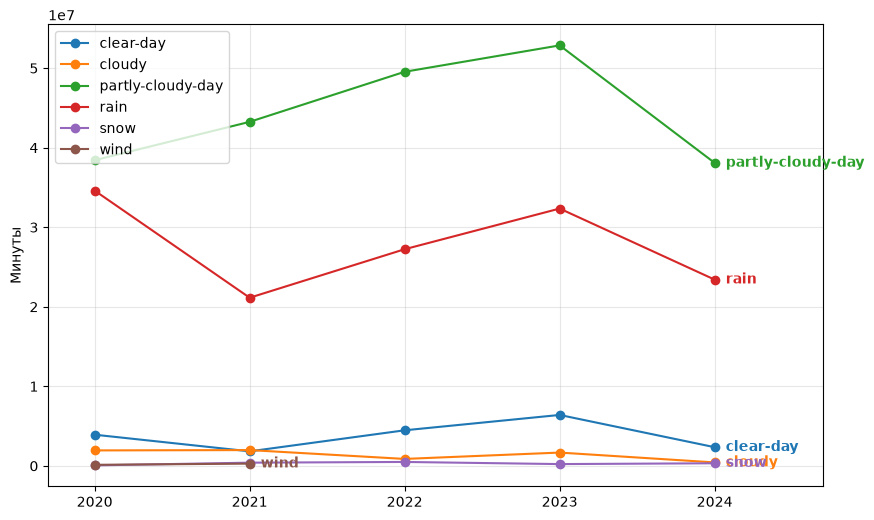

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

lines, labels = {}, {}
for icon in pivot.columns:
    s = pivot[icon].dropna()
    line, = ax.plot(s.index, s.values, marker='o', label=icon)
    lines[icon] = line

    labels[icon] = ax.annotate(
        icon,
        xy=(s.index[-1], s.values[-1]),
        xytext=(8, 0), textcoords='offset points',
        color=line.get_color(), fontweight='bold', va='center'
    )

ax.set_xticks(pivot.index)
ax.set_xlim(pivot.index.min() - 0.3, pivot.index.max() + 0.7)  # место под подписи
ax.set_ylabel('Минуты')
ax.grid(alpha=0.3)
leg = ax.legend()

legend_map = {}
for leg_line, icon in zip(leg.get_lines(), pivot.columns):
    leg_line.set_picker(True)
    leg_line.set_pickradius(8)
    legend_map[leg_line] = icon

plt.show()

- теперь хочу посчитать по количеству дней по все годам при разных погодных условиях

In [14]:
quantity_day = drd_with_weather.groupby(['year', 'icon'])['date'].nunique().to_frame()
quantity_day

date
year icon                   
2020 clear-day            13
     cloudy               10
     partly-cloudy-day   113
     rain                106
     snow                  2
     wind                  1
2021 clear-day            11
     cloudy               12
     partly-cloudy-day   203
     rain                127
     snow                 11
     wind                  1
2022 clear-day            20
     cloudy                4
     partly-cloudy-day   200
     rain                129
     snow                 12
2023 clear-day            23
     cloudy                8
     partly-cloudy-day   193
     rain                139
     snow                  2
2024 clear-day            11
     cloudy                3
     partly-cloudy-day   129
     rain                 95
     snow                  6

- продалжаю подготавливать данные

In [15]:
pivot = quantity_day['date'].unstack('icon')
pivot = pivot[['clear-day', 'cloudy', 'partly-cloudy-day', 'rain', 'snow', 'wind']]  

In [16]:
pivot

icon,clear-day,cloudy,partly-cloudy-day,rain,snow,wind
year,,,,,,
2020,13.0,10.0,113.0,106.0,2.0,1.0
2021,11.0,12.0,203.0,127.0,11.0,1.0
2022,20.0,4.0,200.0,129.0,12.0,NaN
2023,23.0,8.0,193.0,139.0,2.0,NaN
2024,11.0,3.0,129.0,95.0,6.0,NaN


- строю график по количеству дней по всем годам при разных погодных условиях

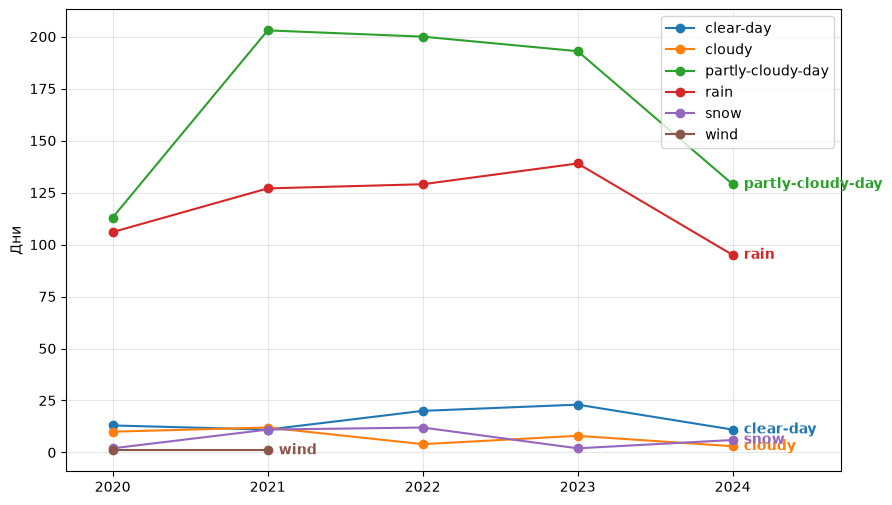

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))

lines, labels = {}, {}
for quantity_day in pivot.columns:
    s = pivot[quantity_day].dropna()
    line, = ax.plot(s.index, s.values, marker='o', label=quantity_day)
    lines[quantity_day] = line

    # подпись с названием сезона на конце линии
    labels[quantity_day] = ax.annotate(
        quantity_day,
        xy=(s.index[-1], s.values[-1]),
        xytext=(8, 0), textcoords='offset points',
        color=line.get_color(), fontweight='bold', va='center'
    )

ax.set_xticks(pivot.index)
ax.set_xlim(pivot.index.min() - 0.3, pivot.index.max() + 0.7)  # место под подписи
ax.set_ylabel('Дни')
ax.grid(alpha=0.3)
leg = ax.legend()

legend_map = {}
for leg_line, quantity_day in zip(leg.get_lines(), pivot.columns):
    leg_line.set_picker(True)
    leg_line.set_pickradius(8)
    legend_map[leg_line] = quantity_day

plt.show()

### Вывод по гипотезе 3 - По подсчетам количество дней когда идет дождь около 600, стоит ли оборудовать 30% всех велосипедов под дождь.

- Считаю что не возможно досчить такого же количества аренды велосипедов,
так как в среднем количество дней с погодой "partly-cloudy-day" на 60-70 дней больше чем с погодными условиями "rain"

- Можно попробовать только сократить разрыв в количестве аренды (в минутах), до оснастив велосипеды